# CSE 242 — Assignment 3 Write-up: SVMs, K-means, and K-NN

**Kangan Qian**, SID 2346765 — Fall 2026, submitted 2026-11-05

The graded implementations live in the three completed Python files
(`assignment3_template.py`, `kmeans_template.py`,
`noisy_classification_template.py`). This notebook imports them, runs the
experiments again, and collects the derivation, plots, and discussion in one
place. Everything runs in the clean virtual environment from the assignment
README with seed 0.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

import assignment3_template as q1
import kmeans_template as q2
import noisy_classification_template as q3

RESULTS = Path("results")

---
## Question 1: Hard-margin linear SVM (30 points)

The training set (the plotting helper labels the points with these IDs):

| ID | (x1, x2) | y | | ID | (x1, x2) | y |
|---|---|---|---|---|---|---|
| 1 | (1, 1) | +1 | | 4 | (0, 0) | −1 |
| 2 | (1, 2) | +1 | | 5 | (1, 0) | −1 |
| 3 | (2, 1) | +1 | | 6 | (0, 1) | −1 |

### Q1(a) — Plot and support vectors (10 points)

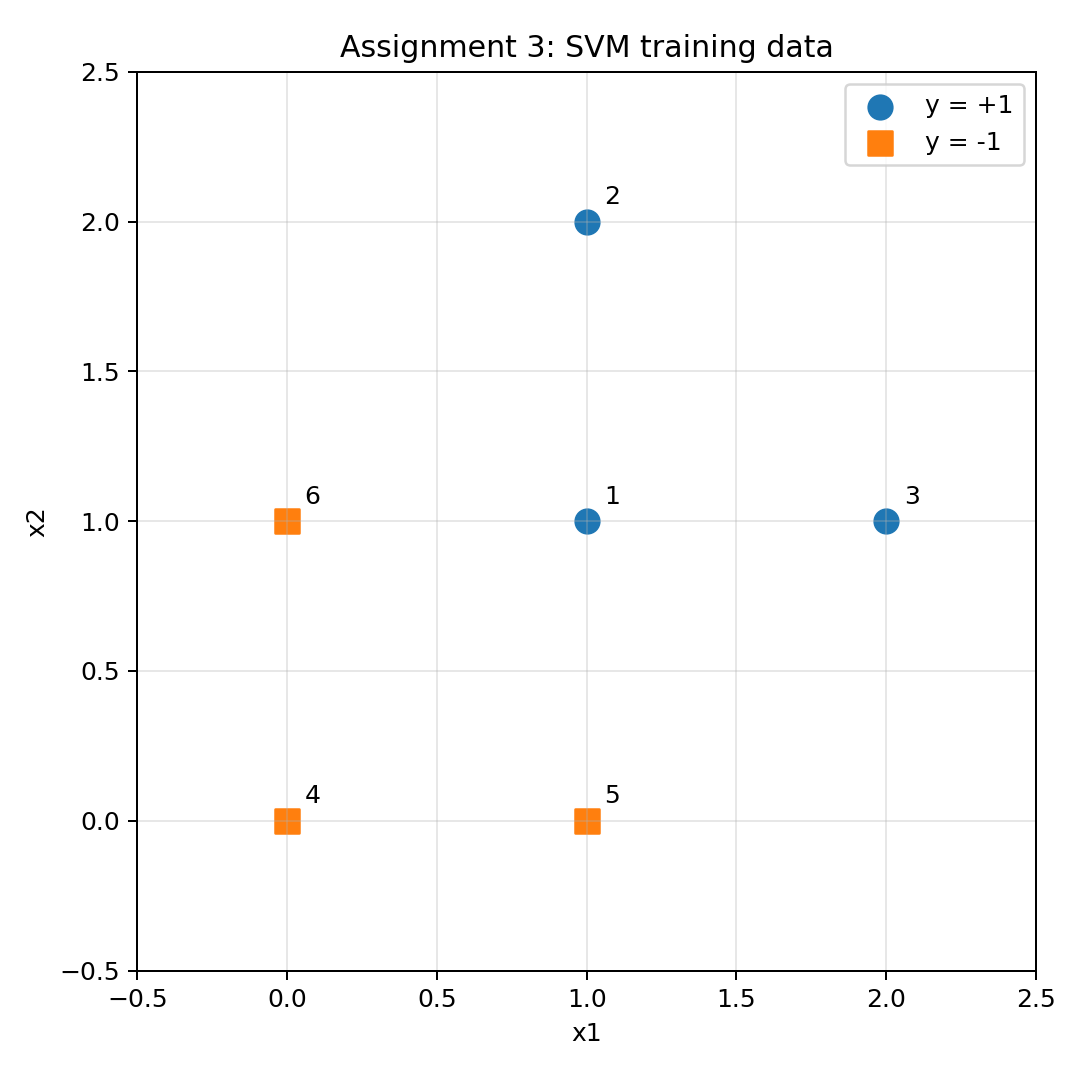

In [2]:
q1.plot_svm_data("svm_data.png")
display(Image(filename="svm_data.png"))

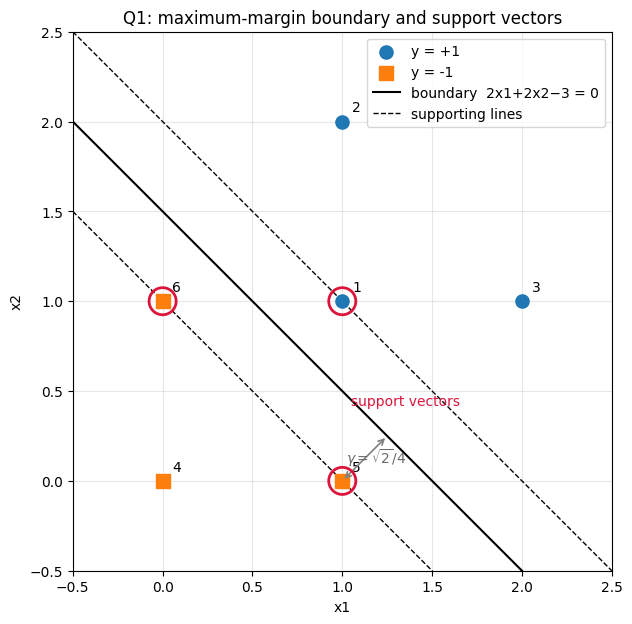

In [3]:
# Report figure: data, candidate maximum-margin boundary, the two supporting
# hyperplanes, and the support vectors circled. This cell only illustrates
# the derivation made below; the numbers come from q1.derive_svm_separator().
(w1, w2), b, margin = q1.derive_svm_separator()

fig, ax = plt.subplots(figsize=(7, 7))
for label, color, marker in ((1, "tab:blue", "o"), (-1, "tab:orange", "s")):
    pts = [x for x, y in zip(q1.SVM_X, q1.SVM_Y) if y == label]
    ax.scatter([p[0] for p in pts], [p[1] for p in pts], color=color,
               marker=marker, s=90, label=f"y = {label:+d}", zorder=3)
for point_id, (x1, x2) in enumerate(q1.SVM_X, start=1):
    ax.annotate(str(point_id), (x1, x2), xytext=(7, 7), textcoords="offset points")

xs = np.linspace(-0.5, 2.5, 100)
ax.plot(xs, (-(w1 * xs) - b) / w2, "k-", label="boundary  2x1+2x2−3 = 0")
ax.plot(xs, (-(w1 * xs) - b + 1) / w2, "k--", lw=1, label="supporting lines")
ax.plot(xs, (-(w1 * xs) - b - 1) / w2, "k--", lw=1)

support_ids = q1.identify_support_vectors()
for pid in support_ids:
    x1, x2 = q1.SVM_X[pid - 1]
    ax.scatter([x1], [x2], s=380, facecolors="none", edgecolors="crimson",
               linewidths=2, zorder=4)
ax.annotate("support vectors", (1.05, 0.42), color="crimson")

# Margin arrow: from support vector 5 (1, 0) to its projection on the
# boundary (1.25, 0.25); length is the geometric margin sqrt(2)/4.
ax.annotate("", xy=(1.25, 0.25), xytext=(1, 0),
            arrowprops=dict(arrowstyle="<->", color="gray", lw=1.2))
ax.annotate(r"$\gamma=\sqrt{2}/4$", (1.02, 0.10), color="dimgray")

ax.set(xlabel="x1", ylabel="x2", title="Q1: maximum-margin boundary and support vectors",
       xlim=(-0.5, 2.5), ylim=(-0.5, 2.5))
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()

**Support vectors: points 1 (1, 1), 5 (1, 0), and 6 (0, 1).**

The margin street of the optimal boundary is bounded by the lines
x1 + x2 = 2 and x1 + x2 = 1, and exactly three points lie on those two
lines: point 1 on the positive side, points 5 and 6 on the negative side.
The by-eye check picks out the same three: (1, 1) is the positive point
closest to the negative class, and (1, 0), (0, 1) are the negative points
closest to the positive class. Removing any of them would allow a wider
separating street, so each one pins the boundary down. The remaining points
are strictly farther out — points 2 (1, 2) and 3 (2, 1) sit at distance
3√2/4 ≈ 1.06 from the boundary and point 4 (0, 0) is equally far on the
negative side — so deleting any of them would not move the separator. That
is what rules them out as support vectors.

### Q1(b) — Boundary and geometric margin (20 points)

**Step 1 — shape of the solution.** Swapping the two coordinates maps the point
set onto itself with the labels preserved ((1,2)↔(2,1), (1,0)↔(0,1), every
other point fixed). The hard-margin optimum is unique, so it must be invariant
under this symmetry, which forces **w1 = w2**.

**Step 2 — canonical scale and intercept.** Write the separator as
w·x + b = 0 with w = (w1, w1). The scale of (w, b) is fixed by the SVM
convention that every support vector lies exactly on its supporting hyperplane,
i.e. yᵢ(w·xᵢ + b) = 1 for the three support vectors found in (a):

- point 1 (1, 1), y = +1: w1 + w1 + b = **1**
- point 5 (1, 0), y = −1: w1 + b = **−1**
- point 6 (0, 1), y = −1: w1 + b = **−1**

Subtracting the last two equations confirms w1 = w2 (symmetry check).
Subtracting the second from the first gives w1 = 2, and back-substitution
gives b = −1 − 2 = **−3**.

**Boundary:** 2·x1 + 2·x2 − 3 = 0, i.e. the line **x1 + x2 = 1.5** with
**w = (2, 2), b = −3**.

**Step 3 — geometric margin.** The margin convention here: the *geometric
margin* is the Euclidean distance from the decision boundary to the closest
training points (the support vectors). For a canonical SVM it equals the
functional margin divided by ‖w‖:

$$\gamma = \min_i \frac{y_i(w\cdot x_i + b)}{\lVert w\rVert} = \frac{1}{\lVert w\rVert} = \frac{1}{2\sqrt{2}} = \frac{\sqrt{2}}{4} \approx 0.3536$$

For example, the distance from point 1 (1, 1) to the boundary is
|2·1 + 2·1 − 3| / ‖w‖ = 1 / (2√2). If one instead wants the **full width
between the two supporting hyperplanes** (2x1+2x2−3 = ±1), it is
2/‖w‖ = 1/√2 ≈ 0.7071 — reported separately per the assignment's convention
note. The code below re-derives the same numbers and verifies that all six
hard-margin constraints hold:

In [4]:
print("Support vectors:", q1.identify_support_vectors())
weights, bias, margin = q1.derive_svm_separator()
print(f"weights w = {weights}, bias b = {bias}")
print(f"geometric margin  1/||w|| = {margin:.6f}  (= sqrt(2)/4 = {np.sqrt(2)/4:.6f})")
print(f"full width between supporting hyperplanes 2/||w|| = {2*margin:.6f}")
print(f"boundary check: point (1,1) -> {weights[0]*1 + weights[1]*1 + bias}")
print()
print("Per-point hard-margin constraints  y*(w.x + b) >= 1:")
for pid, ((x1, x2), y) in enumerate(zip(q1.SVM_X, q1.SVM_Y), start=1):
    functional = y * (weights[0] * x1 + weights[1] * x2 + bias)
    distance = abs(weights[0] * x1 + weights[1] * x2 + bias) / np.hypot(*weights)
    star = "  <- support vector" if functional <= 1 + 1e-9 else ""
    print(f"  point {pid} ({x1},{x2}): y*(w.x+b) = {functional:4.1f}   distance = {distance:.4f}{star}")

Support vectors: [1, 5, 6]
weights w = (2.0, 2.0), bias b = -3.0
geometric margin  1/||w|| = 0.353553  (= sqrt(2)/4 = 0.353553)
full width between supporting hyperplanes 2/||w|| = 0.707107
boundary check: point (1,1) -> 1.0

Per-point hard-margin constraints  y*(w.x + b) >= 1:
  point 1 (1,1): y*(w.x+b) =  1.0   distance = 0.3536  <- support vector
  point 2 (1,2): y*(w.x+b) =  3.0   distance = 1.0607
  point 3 (2,1): y*(w.x+b) =  3.0   distance = 1.0607
  point 4 (0,0): y*(w.x+b) =  3.0   distance = 1.0607
  point 5 (1,0): y*(w.x+b) =  1.0   distance = 0.3536  <- support vector
  point 6 (0,1): y*(w.x+b) =  1.0   distance = 0.3536  <- support vector


All constraints hold with equality exactly at points 1, 5, 6, matching the
visual identification. As a cross-check, a library hard-margin SVM (large C)
returns the same w = (2, 2), b = −3 and the same three support vectors.

---
## Question 2: K-means (30 points)

### Q2(a) — Update steps (15 points)

Both functions are implemented from scratch in `kmeans_template.py`:

- **`update_assignments`** computes all pairwise **squared Euclidean**
  distances between the n points and the k centroids with the expanded form
  ‖a−b‖² = ‖a‖² − 2a·b + ‖b‖² (vectorized, no Python loop over points), then
  takes `argmin` per row. **Tie rule:** a point equidistant from two or more
  centroids goes to the **lowest centroid index**, because `numpy.argmin`
  returns the first minimum — deterministic and independent of data order.
- **`update_centroids`** replaces each centroid with the mean of its members
  and **returns a new array** (the input is never modified in place).
  **Empty-cluster policy:** a cluster with no members **keeps its previous
  centroid**. This matters here because the supplied initializer samples
  starting rows *with replacement*, so duplicate initial centroids (and
  hence an empty cluster) are possible; keeping the old position lets the
  cluster pick up points again on a later iteration instead of crashing.

### Q2(b) — Run and plot (15 points)

Dataset: `make_blobs(n_samples=4000, centers=4, cluster_std=0.60,
random_state=0)` — four Gaussian groups of ≈1000 points each. K-means runs
with seed 0, `max_iterations = 100`, initial centroids drawn by the supplied
with-replacement initializer. The ground-truth group labels are used **only**
for the reference plot below; the clustering itself never sees them.

In [5]:
# Reference plot (ground truth) + all five runs, saved under results/kmeans.
q2.run_experiments(RESULTS / "kmeans", seed=0, max_iterations=100)

k =  2: final centroids saved, cluster sizes = [1017, 2983]
k =  3: final centroids saved, cluster sizes = [1008, 1992, 1000]
k =  4: final centroids saved, cluster sizes = [1000, 998, 1002, 1000]


k =  6: final centroids saved, cluster sizes = [1000, 299, 997, 407, 319, 978]
k = 10: final centroids saved, cluster sizes = [365, 350, 253, 261, 988, 997, 123, 213, 285, 165]
Saved reference plot and 5 cluster plots to results/kmeans


**Reference — the four generating groups:**

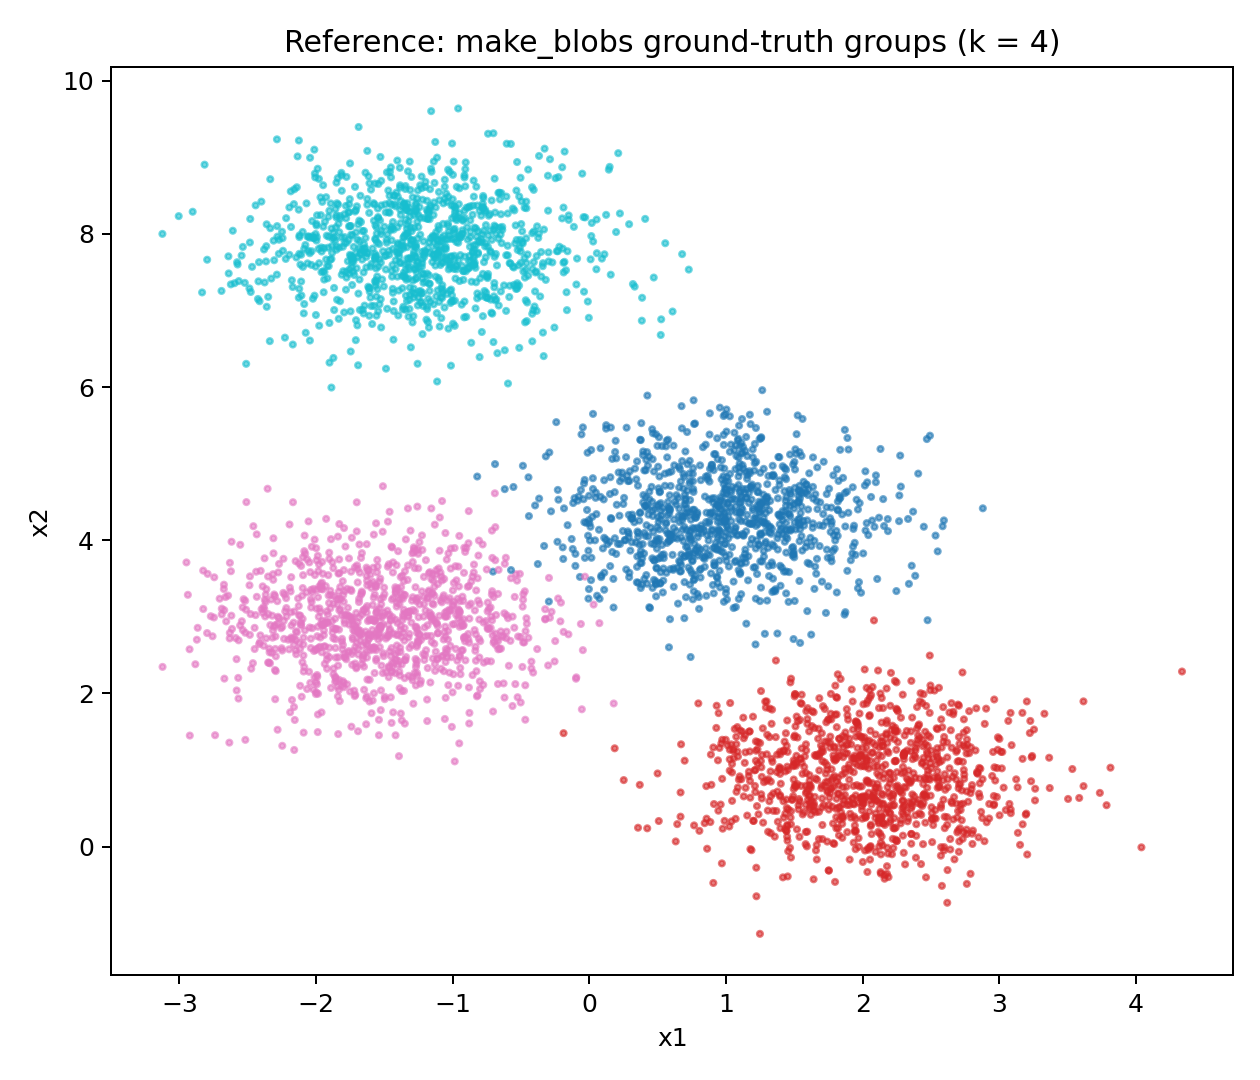

In [6]:
display(Image(filename=str(RESULTS / "kmeans" / "reference_true_labels.png")))

**k = 2:**

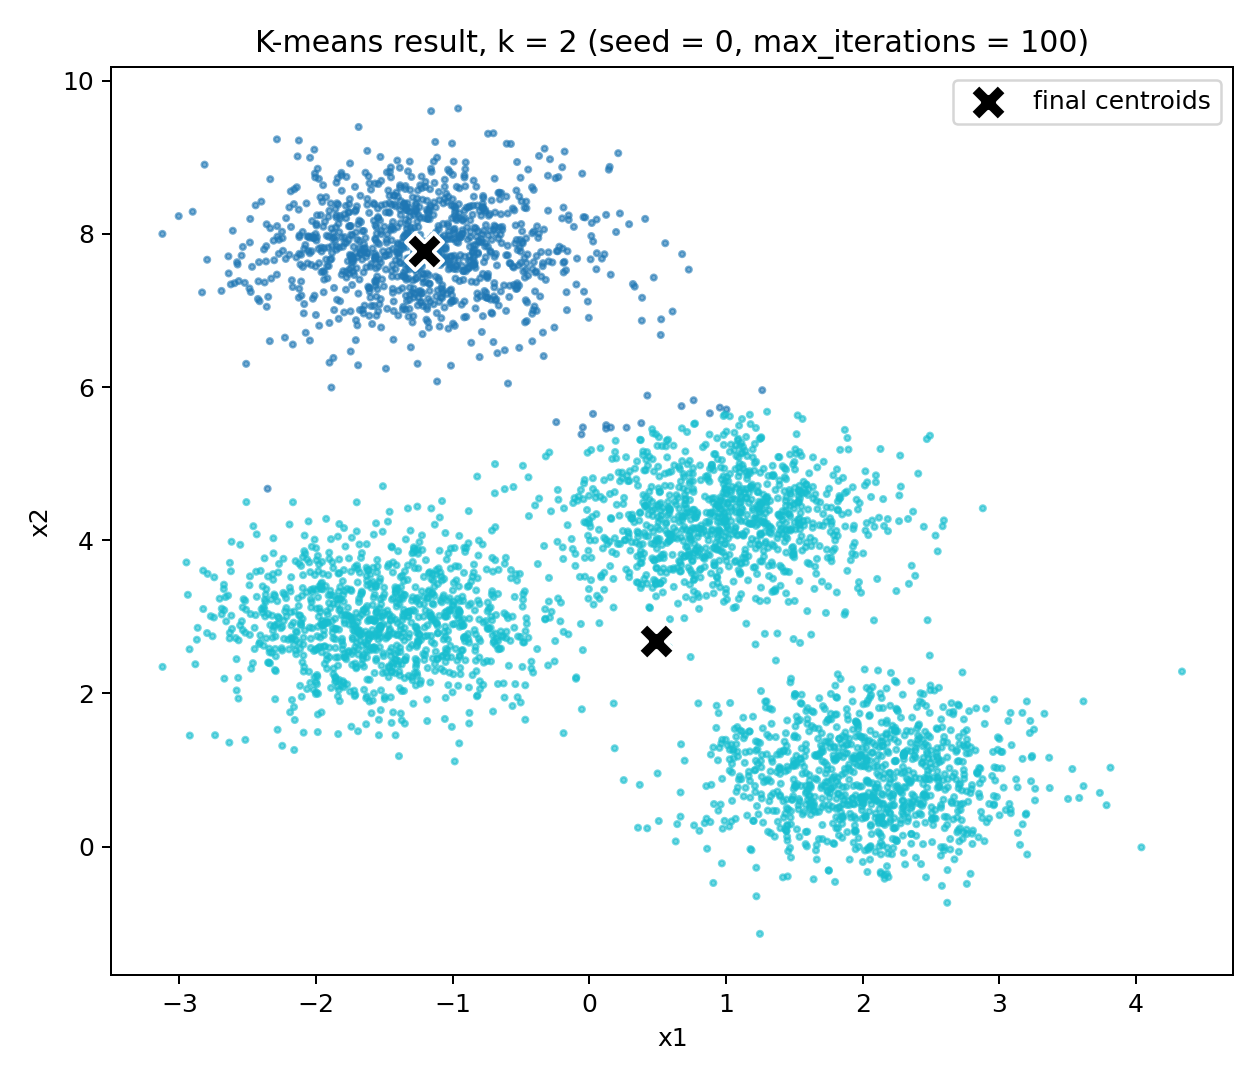

In [7]:
display(Image(filename=str(RESULTS / "kmeans" / "kmeans_k2.png")))

**k = 3:**

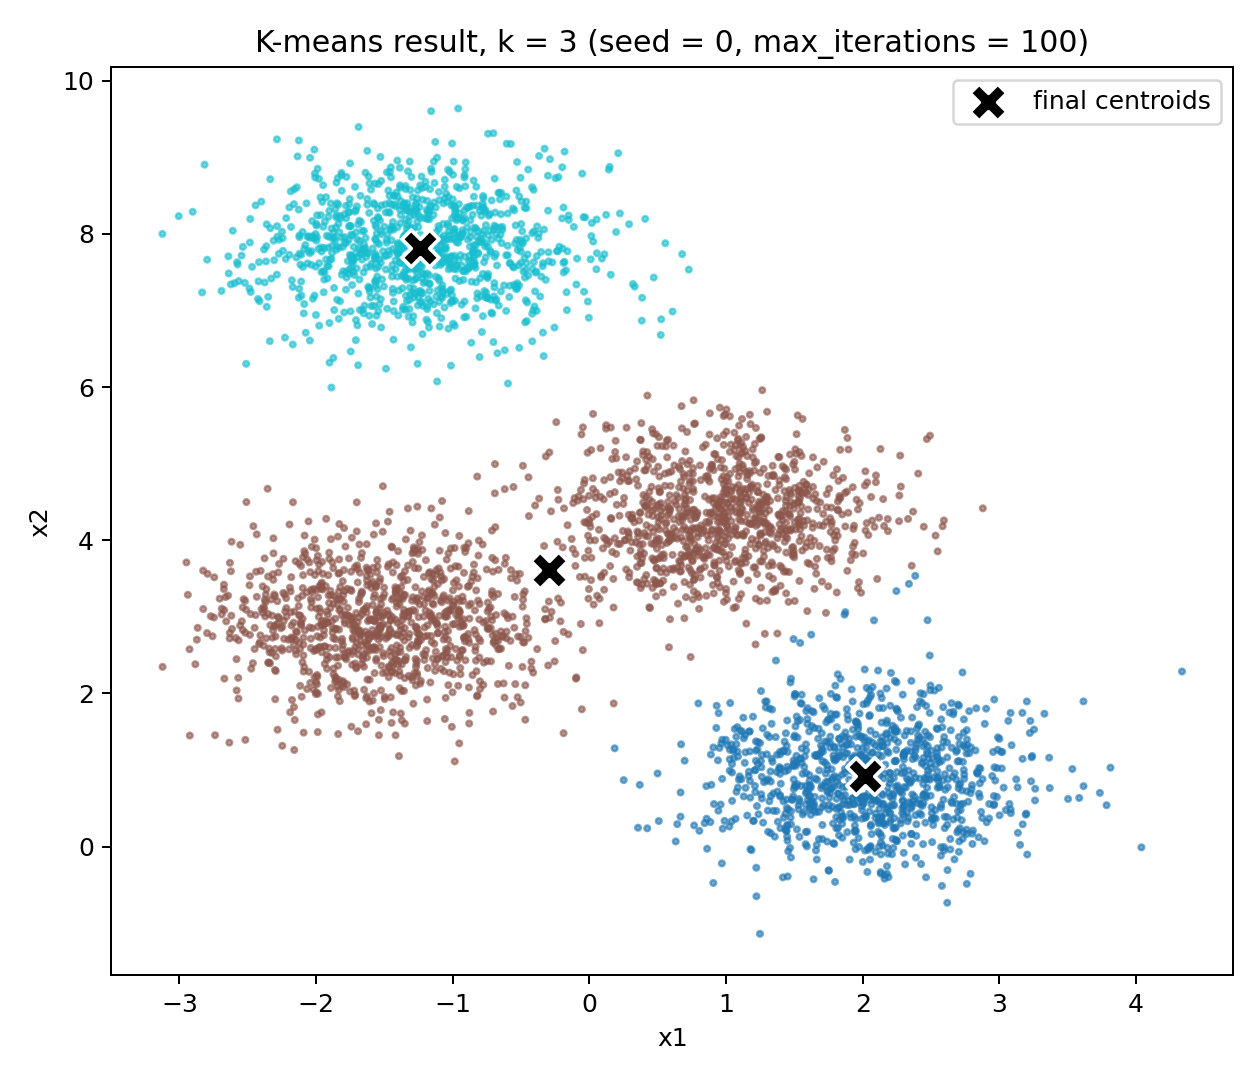

In [8]:
display(Image(filename=str(RESULTS / "kmeans" / "kmeans_k3.png")))

**k = 4:**

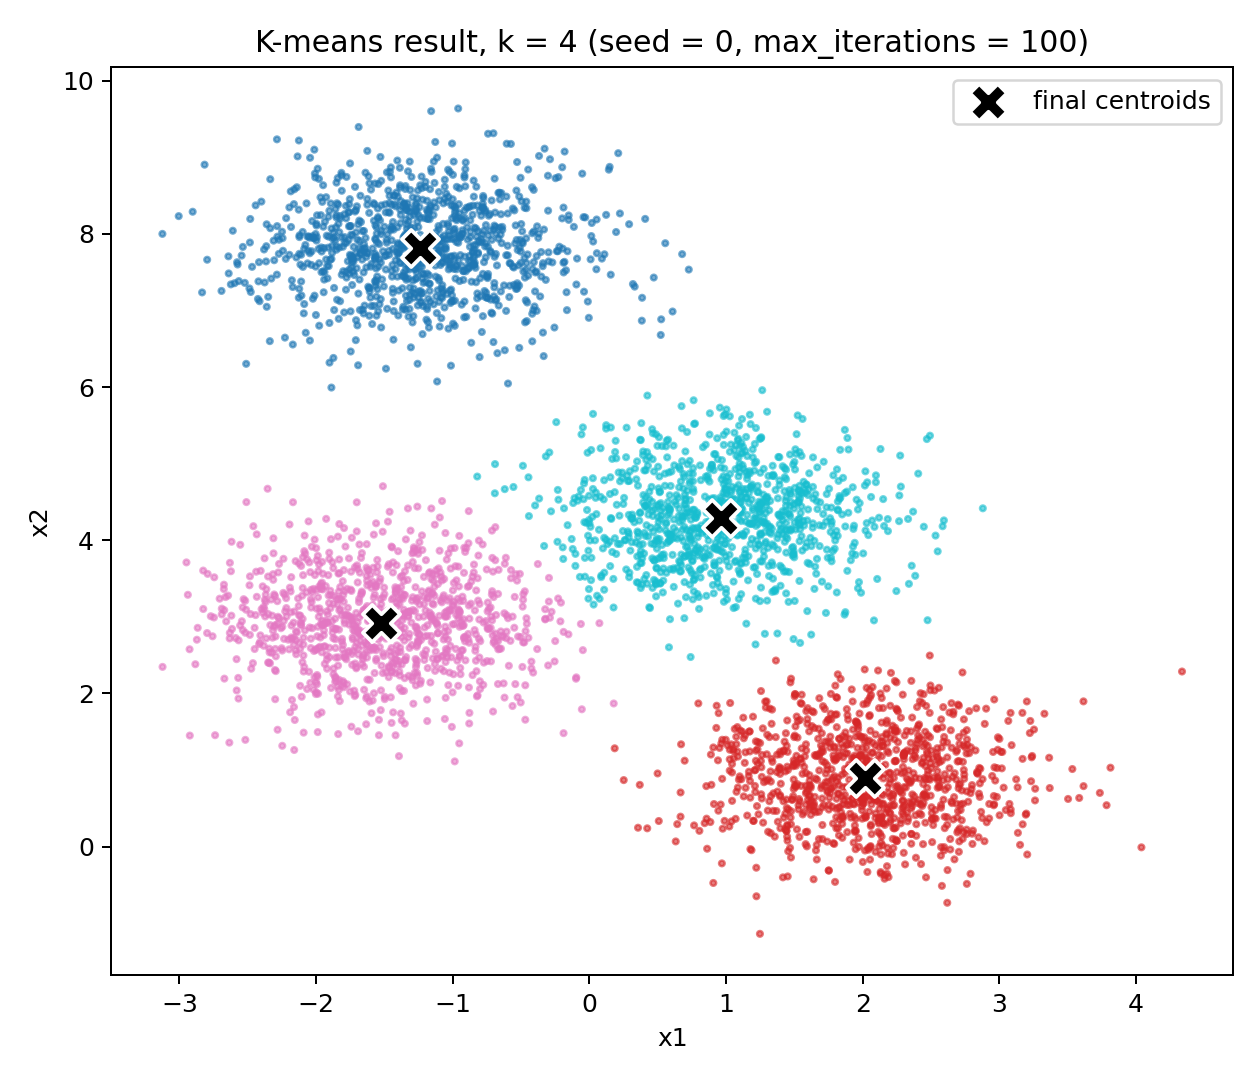

In [9]:
display(Image(filename=str(RESULTS / "kmeans" / "kmeans_k4.png")))

**k = 6:**

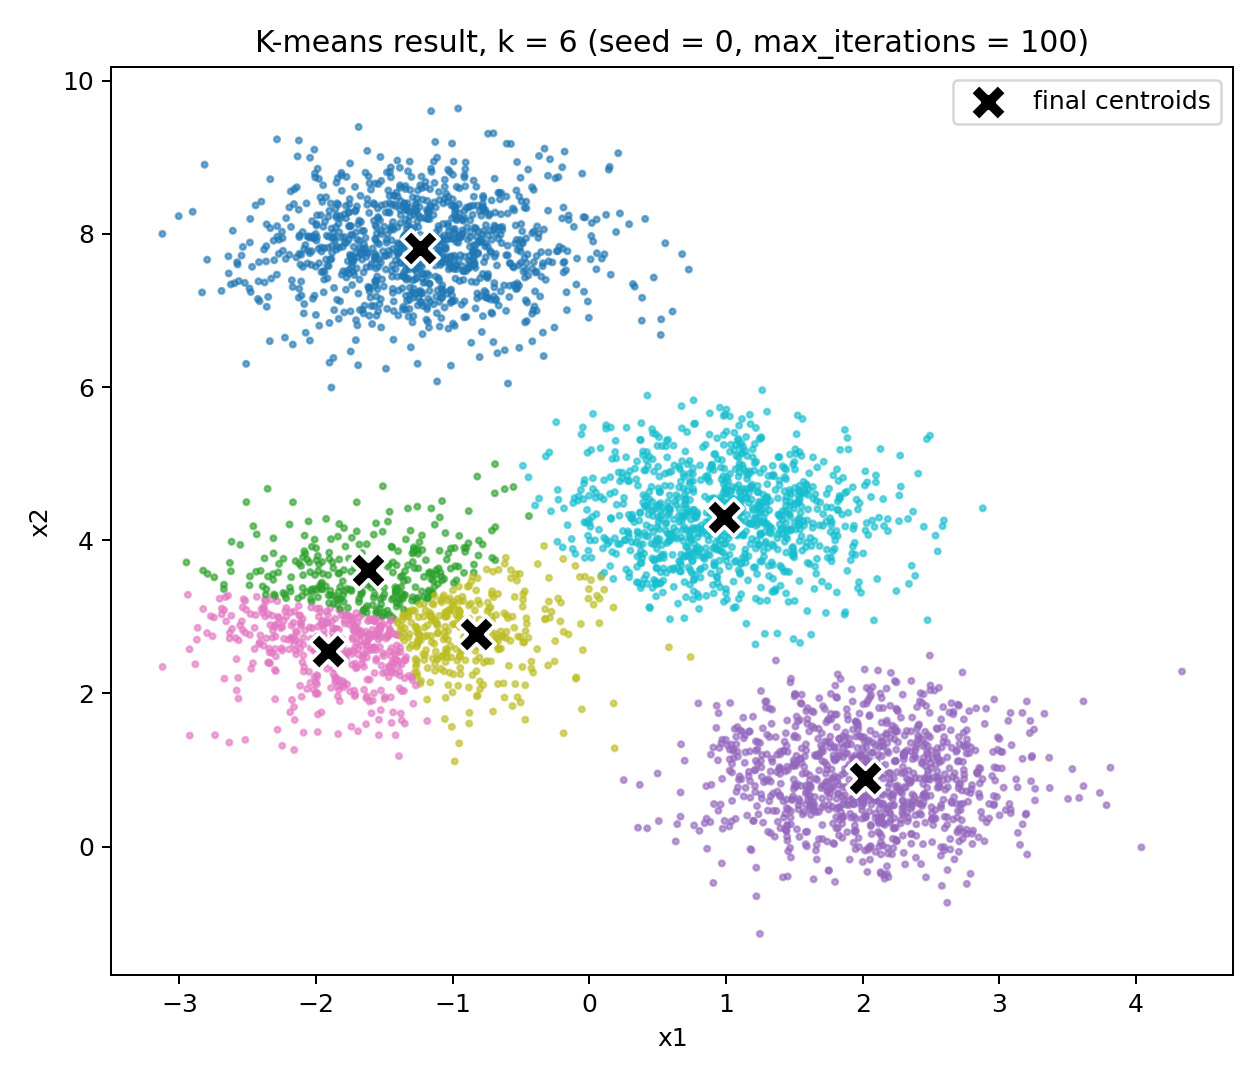

In [10]:
display(Image(filename=str(RESULTS / "kmeans" / "kmeans_k6.png")))

**k = 10:**

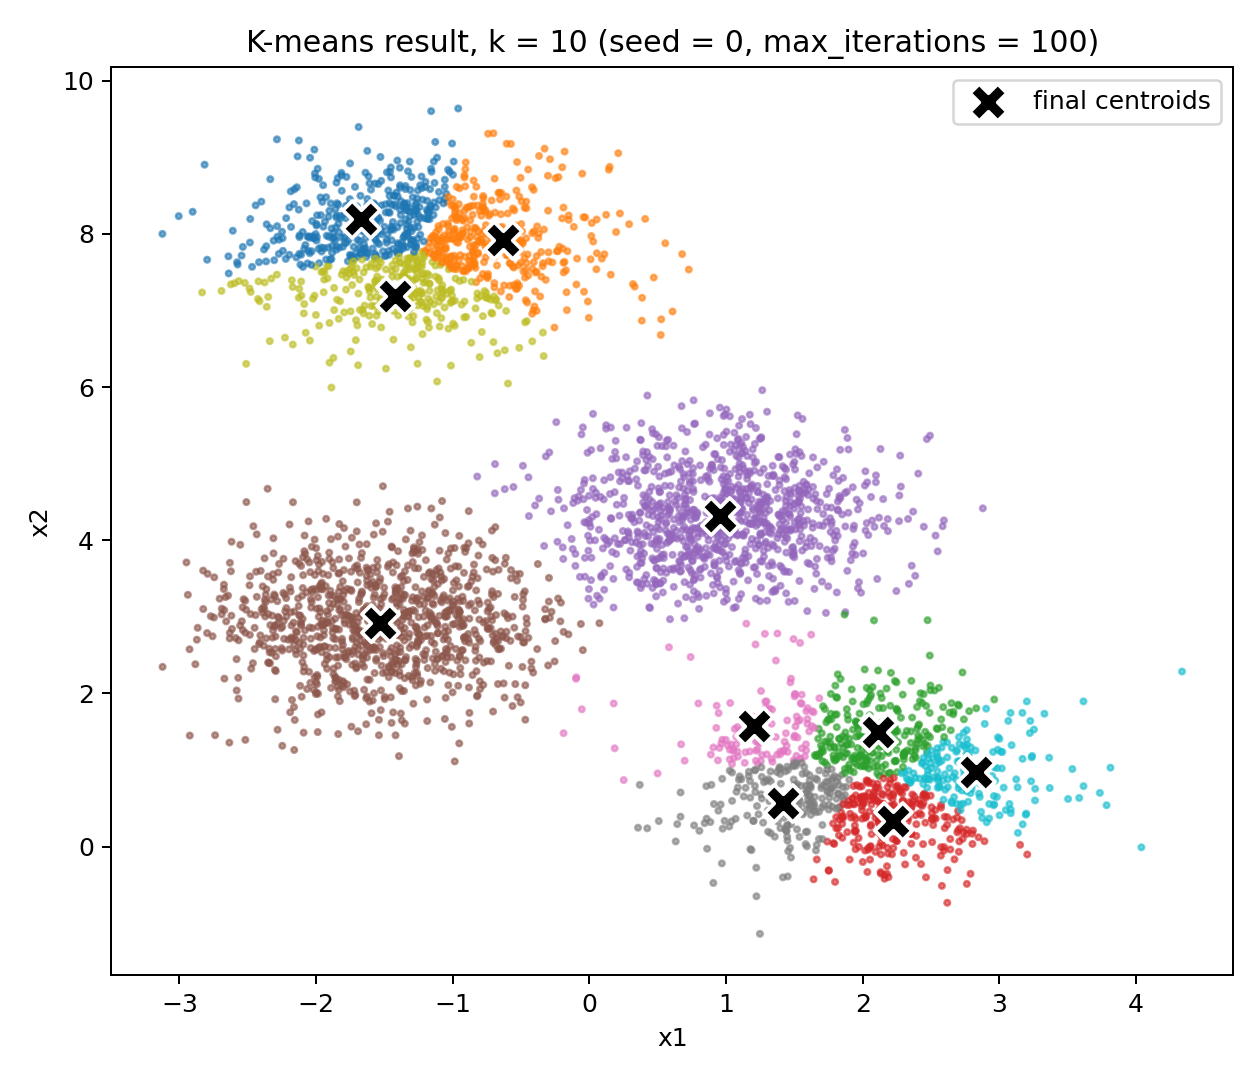

In [11]:
display(Image(filename=str(RESULTS / "kmeans" / "kmeans_k10.png")))

**Discussion.** K-means spends every centroid it is given, so larger k always
makes a finer partition, whether or not more groups actually exist:

- **k = 2** cannot represent four blobs: it isolates the top-left group (the
  most separated one) and lumps the other three into one ≈3,000-point cluster
  whose centroid sits in the empty gap between them.
- **k = 3** keeps the top-left and bottom-right groups whole and spends the
  remaining centroid on the middle, merging the two central groups into one
  ≈2,000-point cluster.
- **k = 4** matches the generating process: one cluster per Gaussian group,
  sizes ≈1,000 each, centroids on the true group centers. This is the only k
  among the five that recovers the truth.
- **k = 6** starts to over-segment: the lower-left group is carved into three
  fragments of roughly 300–400 points while the other three groups stay whole.
- **k = 10** fragments further — two groups survive intact, the top-left
  group splits into 3 pieces and the bottom-right group into 5, with sizes
  down to ≈120. These fragments just slice individual Gaussians into smaller
  Voronoi pieces; they carry no real structure.

Overall: k below 4 merges generating groups, k = 4 recovers them, and k
above 4 splits them, with the extra centroids absorbing within-group
sampling noise. (Cluster colors are arbitrary; the cluster labels themselves
have no fixed meaning.) The run is deterministic for a given seed but not
guaranteed globally optimal — with the with-replacement initializer a
different seed could converge to a worse local minimum, for example two
initial centroids landing in the same blob at k = 4.

---
## Question 3: Noisy-label SVM and K-NN repair (40 points)

Setup common to both parts: one fixed clean training set and one fixed clean
test set, each 1,000 positives from N((1,1), I) and 1,000 negatives from
N((−1,−1), 3I). Test labels stay clean and are used only for final accuracy.
Each of the 20 trials independently corrupts the training labels, and both
methods use the **same** features and the **same** corrupted labels, so the
comparison is paired. The classifier is always an RBF SVM with C = 1,
gamma = 0.01, evaluated on the clean test set.

### Q3(a) — Noisy-label baseline (20 points)

`corrupt_training_labels` draws one uniform random number per training
example. A label is flipped iff its draw passes the threshold selected by its
**original** value: originals +1 flip with probability 0.35, originals −1 with
probability 0.20. Because both decisions read the original labels, no example
can be flipped twice, and the input array is left untouched (a new array is
returned). The baseline SVM is trained directly on the noisy
labels.

### Q3(b) — K-NN label repair (20 points)

`repair_labels_knn` is a pure preprocessing step on the training set:

1. For each training point, find its **5 nearest other training points**
   (Euclidean distance) with `sklearn.neighbors.NearestNeighbors`; the query
   asks for 6 neighbors and drops the first (the point itself).
2. Replace the point's label with the **majority of its five neighbors' noisy
   labels** — with five binary votes the majority is simply "sum > 0".
3. All votes are gathered from the **original noisy-label array** in one
   vectorized indexing step, so no repaired label can influence another and
   the result does not depend on row order. Equal-distance neighbor ties are
   broken by scikit-learn's deterministic ordering (distance, then sample
   index).

No clean label — training or test — ever enters the repair. A fresh SVM is
then trained on the repaired labels and evaluated on the clean test set.
Running the comparison (20 trials, seed 0):

In [12]:
rows = q3.run_comparison(repeats=20, seed=0, neighbors=5,
                         output_path=RESULTS / "noise_comparison.csv")

Trial  1: baseline 0.8345, K-NN repaired 0.8615
Trial  2: baseline 0.8330, K-NN repaired 0.8720


Trial  3: baseline 0.8440, K-NN repaired 0.8675
Trial  4: baseline 0.8445, K-NN repaired 0.8700


Trial  5: baseline 0.8395, K-NN repaired 0.8725
Trial  6: baseline 0.8410, K-NN repaired 0.8715


Trial  7: baseline 0.8405, K-NN repaired 0.8690
Trial  8: baseline 0.7930, K-NN repaired 0.8480


Trial  9: baseline 0.8240, K-NN repaired 0.8615
Trial 10: baseline 0.8425, K-NN repaired 0.8715


Trial 11: baseline 0.8220, K-NN repaired 0.8600
Trial 12: baseline 0.8190, K-NN repaired 0.8645


Trial 13: baseline 0.8470, K-NN repaired 0.8645
Trial 14: baseline 0.8415, K-NN repaired 0.8715


Trial 15: baseline 0.8160, K-NN repaired 0.8715
Trial 16: baseline 0.8285, K-NN repaired 0.8485


Trial 17: baseline 0.8235, K-NN repaired 0.8695
Trial 18: baseline 0.8430, K-NN repaired 0.8700


Trial 19: baseline 0.7840, K-NN repaired 0.8335
Trial 20: baseline 0.7980, K-NN repaired 0.8690

Saved 20 trials to results/noise_comparison.csv
Mean baseline accuracy over 20 trials: 0.8280
Mean K-NN-repaired accuracy over 20 trials: 0.8644
Difference (repaired - baseline): +0.0364


**Per-trial results (saved to `results/noise_comparison.csv`):**

['trial', 'baseline_accuracy', 'knn_accuracy']
1.0000  0.8345  0.8615
2.0000  0.8330  0.8720
3.0000  0.8440  0.8675
4.0000  0.8445  0.8700
5.0000  0.8395  0.8725
6.0000  0.8410  0.8715
7.0000  0.8405  0.8690
8.0000  0.7930  0.8480
9.0000  0.8240  0.8615
10.0000  0.8425  0.8715
11.0000  0.8220  0.8600
12.0000  0.8190  0.8645
13.0000  0.8470  0.8645
14.0000  0.8415  0.8715
15.0000  0.8160  0.8715
16.0000  0.8285  0.8485
17.0000  0.8235  0.8695
18.0000  0.8430  0.8700
19.0000  0.7840  0.8335
20.0000  0.7980  0.8690


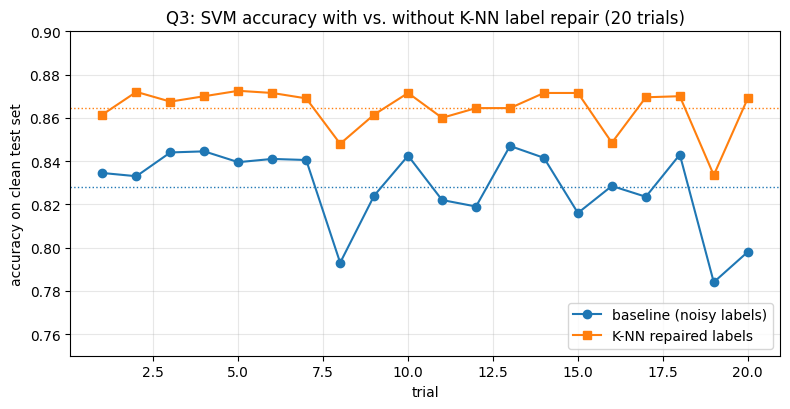

In [13]:
with open(RESULTS / "noise_comparison.csv") as handle:
    reader = list(csv.reader(handle))
print(reader[0])
for row in reader[1:]:
    print("  ".join(f"{float(v):.4f}" for v in row))

baseline = np.array([float(r[1]) for r in reader[1:]])
knn = np.array([float(r[2]) for r in reader[1:]])

fig, ax = plt.subplots(figsize=(8, 4.2))
trials = np.arange(1, len(baseline) + 1)
ax.plot(trials, baseline, "o-", label="baseline (noisy labels)")
ax.plot(trials, knn, "s-", label="K-NN repaired labels")
ax.axhline(baseline.mean(), color="C0", ls=":", lw=1)
ax.axhline(knn.mean(), color="C1", ls=":", lw=1)
ax.set(xlabel="trial", ylabel="accuracy on clean test set",
       title="Q3: SVM accuracy with vs. without K-NN label repair (20 trials)")
ax.set_ylim(0.75, 0.90)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

In [14]:
diff = knn - baseline
print(f"mean baseline accuracy: {baseline.mean():.4f} (std {baseline.std(ddof=1):.4f})")
print(f"mean K-NN-repaired accuracy: {knn.mean():.4f} (std {knn.std(ddof=1):.4f})")
print(f"mean difference (repaired - baseline): {knn.mean() - baseline.mean():+.4f}")
print(f"trials where repair improved: {(diff > 0).sum()} / {len(diff)}; "
      f"tied: {(diff == 0).sum()}; hurt: {(diff < 0).sum()}")

# Context (extra, not required): accuracy of the same SVM on *clean* labels.
rng = np.random.default_rng(0)
train_x, train_y = q3.generate_clean_split(rng)
test_x, test_y = q3.generate_clean_split(rng)
clean_accuracy = q3.train_and_evaluate(train_x, train_y, test_x, test_y)
print(f"reference, no label noise at all: {clean_accuracy:.4f}")

mean baseline accuracy: 0.8280 (std 0.0183)
mean K-NN-repaired accuracy: 0.8644 (std 0.0102)
mean difference (repaired - baseline): +0.0364
trials where repair improved: 20 / 20; tied: 0; hurt: 0
reference, no label noise at all: 0.8670


**Results.** Mean accuracy rose from 0.8280 (baseline) to 0.8644 (repaired),
a gain of +3.6 points, and the repaired SVM won every individual trial, with
per-trial gains between 1.75 and 7.1 points. For reference, the same SVM
trained on the untouched labels reaches about 0.97, so the asymmetric noise
costs roughly 14 points and the repair recovers about a quarter of that.

**Why it works here.** Counting over all 20 trials shows what the repair
actually does. The corruption flips 10,808 of the 40,000 training labels;
the 5-NN vote corrects 7,650 of them (71%) but also rewrites 7,743 labels
that were correct before the repair. The raw counts nearly cancel, yet
accuracy improves, because the two kinds of changes are not equivalent. A
randomly flipped label usually sits among neighbors of its true class, so
the vote reliably restores it. The labels the vote removes are concentrated
near the class boundary, where the neighborhood is dominated by the other
class; there the vote replaces the generated label with the locally dominant
one, which is closer to what an optimal classifier would predict at those
coordinates anyway. The SVM ends up fitting a target that agrees with the
local structure of the features instead of fighting it.

**When it would hurt.** The same mechanism is also the risk. Near a boundary
or in heavily overlapped classes the vote rewrites genuine labels (7,743
times here); with stronger noise, worse separation, or less informative
features, that rewriting can dominate and drag accuracy down. The
improvement here is a property of this dataset — well-separated, tight
Gaussians — not a guarantee for every noisy-label problem.

---
## Acknowledgment of outside help

The approach for all three questions came from a written draft I prepared
before any code existed: which points should be the support vectors and how
to check that by eye, solving the support-vector equations y·(w·x + b) = ±1
by hand for w and b, reporting the margin as γ = 1/‖w‖ with the full width
2/‖w‖ called out separately, breaking K-means distance ties toward the lower
centroid index and letting empty clusters keep their centroid, applying each
noise flip to the original labels only once, and repairing every label from
the same snapshot of the noisy labels with a 5-NN majority vote. I gave the
draft to Claude Code (GLM model, VS Code extension), which implemented the
three template files along these lines, ran the experiments, and produced
the plots, CSV, and this report; the transcript is in
`AI_assistance_log.md`.

I checked the results myself: an off-the-shelf linear SVM reproduces my Q1
derivation exactly, the Q2 plots match the reference grouping, and the Q3
summary numbers agree with the per-trial CSV. No other outside help was
used.